In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ai4_tools as ai4
import os
import time


from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, learning_curve, train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=UserWarning)
RUNTIME = ai4.show_runtime()

Runtime: Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz (2 cores, 12.7 GB) | CPU only | Python 3.13.18


### Data

In [2]:
# Loading the dataset
MY_FILE = "stroke-prediction.csv"   # your file name, as a string

if not os.path.exists(MY_FILE):   # Colab: pick the file in the upload dialog
    from google.colab import files
    files.upload()

raw = pd.read_csv(MY_FILE)
print(raw.shape)
raw.head()

(5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
# Target and ID removal
TARGET = "stroke"   # the column you predict, as a string (see the data sheet)
DROP = ["id"]   # columns the model must not see, or [] if none (Tutorial 1, section 2)

df = raw.drop(columns=DROP)

# A column with a different value on every row only labels the row: it cannot generalise.
labels = [c for c in df.columns if c != TARGET and df[c].nunique() == len(df)]
ai4.check("1.1 the target is a column", TARGET in df.columns, "check the spelling against the data sheet")
ai4.check("1.2 no ID column left", not labels, "{} has a different value on every row: add it to DROP".format(labels))

PASS  1.1 the target is a column
PASS  1.2 no ID column left


True

### Exploration and cleaning

In [4]:
# Data Overview
# One row per column: its type, missing values, distinct values, and the range of the numbers.
def overview(d):
    numbers = d.select_dtypes("number")
    return pd.DataFrame({"type": d.dtypes.astype(str), "missing": d.isna().sum(),
                         "distinct": d.nunique(), "min": numbers.min(), "max": numbers.max()})

overview(df)

,type,missing,distinct,min,max
age,float64,0,104,0.08,82.00
avg_glucose_level,float64,0,3979,55.12,271.74
bmi,float64,201,418,10.30,97.60
ever_married,object,0,2,NaN,NaN
gender,object,0,3,NaN,NaN
heart_disease,int64,0,2,0.00,1.00
hypertension,int64,0,2,0.00,1.00
residence_type,object,0,2,NaN,NaN
smoking_status,object,0,4,NaN,NaN
stroke,int64,0,2,0.00,1.00


In [5]:
# No additional cleaning is needed
# Because we want to avoid removing valid patient records or making assumptions about BMI measurements without enough evidence

In [6]:
# Remove any target missing-value and Check data
df = df.dropna(subset=[TARGET])   # a row without a target cannot be used
# Check whether any rows that have numbers are not accidentally stored as text
text_numbers = [c for c in df.columns if c != TARGET and df[c].dtype == object and df[c].nunique() > 20]
ai4.check("2.1 no numbers stored as text", not text_numbers,
          "{} is text with many distinct values: convert it in the cell above".format(text_numbers))
# Display the updated dataset summary
overview(df)

PASS  2.1 no numbers stored as text


,type,missing,distinct,min,max
age,float64,0,104,0.08,82.00
avg_glucose_level,float64,0,3979,55.12,271.74
bmi,float64,201,418,10.30,97.60
ever_married,object,0,2,NaN,NaN
gender,object,0,3,NaN,NaN
heart_disease,int64,0,2,0.00,1.00
hypertension,int64,0,2,0.00,1.00
residence_type,object,0,2,NaN,NaN
smoking_status,object,0,4,NaN,NaN
stroke,int64,0,2,0.00,1.00


###Class balance

In [7]:
# The share of each class: what would always predicting the commonest one score?
df[TARGET].value_counts(normalize=True)
# This is very useful because stroke is an imbalanced dataset with a 95.1% no stroke proportion
# This is why we use ROC AUC as our primary metric and recall as secondary, because accuracy alone would not be enough
# Because if the model assumed no stroke for all cases it would be 95.1% accurate even though it missed alot of strokes!!

,proportion
stroke,
0,0.951272
1,0.048728


### Split

In [8]:
# Define X and y from the stroke dataset
y = df[TARGET]
X = df.drop(columns=[TARGET])

# Splitting training and test data
# 80% to train, 20% to test. What keeps the class shares the same in both? (Tutorial 1, section 2)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

shares = pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)})
ai4.check("3.1 the split is stratified", (shares["train"] - shares["test"]).abs().max() < 0.01,
          "the class shares differ between the two parts: see the comment above the split")
shares.round(3)

PASS  3.1 the split is stratified


,train,test
stroke,,
0,0.951,0.951
1,0.049,0.049


###Baseline

In [9]:
# As in Tutorial 1, with one addition: imputers fill missing values, learning from the
# training rows only. Numbers: median. Text: commonest value, then one-hot.
numeric_cols = X.select_dtypes("number").columns.tolist()
text_cols = [c for c in X.columns if c not in numeric_cols]
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median"))]), numeric_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), text_cols),
])
pipe = Pipeline([("prep", preprocess), ("model", GradientBoostingClassifier(loss='log_loss', learning_rate=0.1, n_estimators=100, max_depth=3, random_state=0))])

# keep the test set untouched until we fit and evaluate through cross-validation
# We want the median to be learned form the training data inside the pipeline only, not from the entire dataset
# This is important to prevent data leakage inside during cross-validation
#pipe.fit(X_train, y_train)
#pred = pipe.predict(X_test)

# No "StandardScaler" used here. Whilst it is beneficial for LogisticRegression because it uses coefficients in its optimisation, gradient boosting uses decision trees, which do not require scaling, becuase they split values based on thresholds
# For missing numerical values, median imputation will be used because the median is less affected to data outliers than the mean

### Five-fold Stratified Cross-Validation & Model Performance

In [10]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
# Training and validation ROC AUC, and recall for each fold
# Fit time and scoring time for each fold
# Fit time is the time taken to train the pipeline on each fold
# Scoring time is the time taken to test the trained model and calculate its acccuracy and evaluation metrics like ROC AUC and recall
s = cross_validate(
    pipe,
    X_train,
    y_train,
    cv=cv,
    scoring=["roc_auc", "recall"],
    return_train_score=True
)

In [11]:
s


{'fit_time': array([1.20824933, 1.4186132 , 1.41742301, 1.28256321, 2.69149923]),
 'score_time': array([0.06636763, 0.04277492, 0.06194711, 0.05352449, 0.1275661 ]),
 'test_roc_auc': array([0.83296915, 0.81616324, 0.86131105, 0.86070463, 0.87110682]),
 'train_roc_auc': array([0.95160002, 0.94641352, 0.95438382, 0.95335905, 0.95281301]),
 'test_recall': array([0.  , 0.05, 0.05, 0.  , 0.1 ]),
 'train_recall': array([0.2327044 , 0.20754717, 0.2327044 , 0.225     , 0.20754717])}

### Balanced Class Weights

In [12]:
experiments = {
    "baseline": pipe,
    "balanced weights": Pipeline([
        ("prep", preprocess),
        ("model", GradientBoostingClassifier(
            loss="log_loss",
            learning_rate=0.1,
            n_estimators=100,
            max_depth=3,
            random_state=0
        ))
    ])
}

rows = []

for name, candidate in experiments.items():

    if name == "baseline":
        s = cross_validate(
            candidate,
            X_train,
            y_train,
            cv=cv,
            scoring=["roc_auc", "recall", "precision"],
            return_train_score=False
        )

        rows.append({
            "experiment": name,
            "ROC AUC": s["test_roc_auc"].mean(),
            "ROC AUC spread": s["test_roc_auc"].std(),
            "recall": s["test_recall"].mean(),
            "precision": s["test_precision"].mean(),
            "fit time (s)": s["fit_time"].mean()
        })

    else:
        fold_results = []


        for train_idx, val_idx in cv.split(X_train, y_train):
            X_fold_train = X_train.iloc[train_idx]
            X_fold_val = X_train.iloc[val_idx]
            y_fold_train = y_train.iloc[train_idx]
            y_fold_val = y_train.iloc[val_idx]

            weights = compute_sample_weight("balanced", y_fold_train)

            start = time.perf_counter()
            candidate.fit(
                X_fold_train,
                y_fold_train,
                model__sample_weight=weights
            )
            fit_time = time.perf_counter() - start

            pred = candidate.predict(X_fold_val)
            prob = candidate.predict_proba(X_fold_val)[:, 1]

            fold_results.append({
                "roc_auc": roc_auc_score(y_fold_val, prob),
                "recall": recall_score(y_fold_val, pred),
                "precision": precision_score(
                    y_fold_val, pred, zero_division=0
                ),
                "fit_time": fit_time
            })

        balanced_results = pd.DataFrame(fold_results)

        rows.append({
            "experiment": name,
            "ROC AUC": balanced_results["roc_auc"].mean(),
            "ROC AUC spread": balanced_results["roc_auc"].std(),
            "recall": balanced_results["recall"].mean(),
            "precision": balanced_results["precision"].mean(),
            "fit time (s)": balanced_results["fit_time"].mean()
        })

ai4.check("6.1 at least one experiment besides the baseline", len(experiments) >= 2)

pd.DataFrame(rows).round(4)

PASS  6.1 at least one experiment besides the baseline


,experiment,ROC AUC,ROC AUC spread,recall,precision,fit time (s)
0,baseline,0.8485,0.0205,0.0400,0.3267,1.4884
1,balanced weights,0.8362,0.0199,0.6587,0.1596,1.1382


### Experiment: Compare 50 trees vs 100 trees vs 500 trees

---



In [13]:
experiments = {
    "baseline (100 trees)": pipe,

    "fewer estimators (50 trees)": Pipeline([("prep", preprocess), ("model", GradientBoostingClassifier(loss='log_loss', learning_rate=0.1, n_estimators=50, max_depth=3, random_state=0))]),

    "more estimators (500 trees)": Pipeline([("prep", preprocess), ("model", GradientBoostingClassifier(loss='log_loss', learning_rate=0.1, n_estimators=500, max_depth=3, random_state=0))]),
}

rows = []
for name, candidate in experiments.items():
    s = cross_validate(candidate, X_train, y_train, cv=cv, scoring=["roc_auc", "recall"], return_train_score = True)

    rows.append({"experiment": name,
                 "training ROC AUC": s["train_roc_auc"].mean(),
                 "validation ROC AUC": s["test_roc_auc"].mean(),
                 "ROC AUC spread": s["test_roc_auc"].std(),
                 "training recall": s["train_recall"].mean(),
                 "validation recall": s["test_recall"].mean(),
                 "fit time (s)": s["fit_time"].mean()})

ai4.check("6.1 at least one experiment besides the baseline", len(experiments) >= 2,
          "add a variant to the dictionary above")
pd.DataFrame(rows).round(4)


PASS  6.1 at least one experiment besides the baseline


,experiment,training ROC AUC,validation ROC AUC,ROC AUC spread,training recall,validation recall,fit time (s)
0,baseline (100 trees),0.9517,0.8485,0.0205,0.2211,0.0400,0.7979
1,fewer estimators (50 trees),0.9267,0.8528,0.0207,0.1030,0.0150,0.3487
2,more estimators (500 trees),0.9989,0.8133,0.0217,0.8203,0.0903,3.4576


### Experiment: Compare Max depth = 1, 2, 3

---



In [14]:
experiments = {
    "baseline (depth 3)":  Pipeline([("prep", preprocess), ("model", GradientBoostingClassifier(loss='log_loss', learning_rate=0.1, n_estimators=50, max_depth=3, random_state=0))]),

    "very simple trees  (depth 1)": Pipeline([("prep", preprocess), ("model", GradientBoostingClassifier(loss='log_loss', learning_rate=0.1, n_estimators=50, max_depth=1, random_state=0))]),

    "moderately simple trees (depth 2)": Pipeline([("prep", preprocess), ("model", GradientBoostingClassifier(loss='log_loss', learning_rate=0.1, n_estimators=50, max_depth=2, random_state=0))]),
}

rows = []
for name, candidate in experiments.items():
    s = cross_validate(candidate, X_train, y_train, cv=cv, scoring=["roc_auc", "recall"], return_train_score = True)

    rows.append({"experiment": name,
                 "training ROC AUC": s["train_roc_auc"].mean(),
                 "validation ROC AUC": s["test_roc_auc"].mean(),
                 "ROC AUC spread": s["test_roc_auc"].std(),
                 "training recall": s["train_recall"].mean(),
                 "validation recall": s["test_recall"].mean(),
                 "fit time (s)": s["fit_time"].mean()})

ai4.check("6.1 at least one experiment besides the baseline", len(experiments) >= 2,
          "add a variant to the dictionary above")
pd.DataFrame(rows).round(4)


PASS  6.1 at least one experiment besides the baseline


,experiment,training ROC AUC,validation ROC AUC,ROC AUC spread,training recall,validation recall,fit time (s)
0,baseline (depth 3),0.9267,0.8528,0.0207,0.1030,0.015,0.4169
1,very simple trees (depth 1),0.8632,0.8493,0.0291,0.0000,0.000,0.2440
2,moderately simple trees (depth 2),0.8920,0.8542,0.0237,0.0176,0.015,0.2812


### Threshold Investigation

In [15]:
# Threshold investigation on the SELECTED model (balanced weights, 50 trees, lr 0.1, depth 1).
# Uses training data only (cross-validation). The test set is NOT touched here.
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import precision_score, recall_score, roc_auc_score

BEST_PARAMS = {"model__n_estimators": 50, "model__learning_rate": 0.1, "model__max_depth": 1}
RECALL_TARGET = 0.80   # <-- the group's agreed constraint ("catch at least 80% of strokes"). Change if different.

oof_proba = np.zeros(len(y_train))
for tr, va in cv.split(X_train, y_train):
    m = clone(pipe).set_params(**BEST_PARAMS)
    m.fit(X_train.iloc[tr], y_train.iloc[tr],
          model__sample_weight=compute_sample_weight("balanced", y_train.iloc[tr]))
    oof_proba[va] = m.predict_proba(X_train.iloc[va])[:, 1]

rows = []
for t in [0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1]:
    p = (oof_proba >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(y_train, p, zero_division=0),
                 "recall": recall_score(y_train, p),
                 "share flagged": p.mean()})
threshold_table = pd.DataFrame(rows).round(3)
display(threshold_table)

# Highest threshold that still meets the recall constraint (= fewest people flagged)
ok = threshold_table[threshold_table["recall"] >= RECALL_TARGET]
THRESHOLD = float(ok["threshold"].max()) if len(ok) else 0.5
print("Chosen threshold:", THRESHOLD,
      "(highest threshold with CV recall >= {:.0%})".format(RECALL_TARGET) if len(ok)
      else "(no threshold met the target, falling back to 0.5)")

,threshold,precision,recall,share flagged
0,0.9,0.000,0.000,0.000
1,0.8,0.208,0.191,0.045
2,0.7,0.182,0.608,0.162
3,0.6,0.160,0.719,0.219
4,0.5,0.126,0.859,0.332
5,0.4,0.112,0.889,0.386
6,0.3,0.100,0.925,0.451
7,0.2,0.090,0.965,0.521
8,0.1,0.078,0.985,0.616


Chosen threshold: 0.5 (highest threshold with CV recall >= 80%)


### Hyperparameter tuning (GridSearchCV)   

In [16]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(pipe, {"model__n_estimators": [50, 100, 500],
                             "model__learning_rate": [0.001, 0.01, 0.1],
                             "model__max_depth": [1, 2, 3]
                             },
                             cv=cv, scoring="roc_auc", return_train_score=True)

search.fit(X_train, y_train)

print("best parameters:", search.best_params_)
print("Best CV ROC AUC:", search.best_score_)

best parameters: {'model__learning_rate': 0.01, 'model__max_depth': 3, 'model__n_estimators': 500}
Best CV ROC AUC: 0.8549365107784132


### GridSearchCV Results

In [17]:
r = pd.DataFrame(search.cv_results_)

print("best n_estimators:", search.best_params_["model__n_estimators"])
print("best learning rate:", search.best_params_["model__learning_rate"])
print("best max depth:", search.best_params_["model__max_depth"])

pd.DataFrame({
    "model__n_estimators": r["param_model__n_estimators"],
    "model__learning_rate": r["param_model__learning_rate"],
    "model__max_depth": r["param_model__max_depth"],
    "training ROC AUC": r["mean_train_score"],
    "validation ROC AUC": r["mean_test_score"],
    "validation ROC AUC spread": r["std_test_score"],
    "mean fit time (s)": r["mean_fit_time"],
    "mean score time (s)": r["mean_score_time"]
}).sort_values("validation ROC AUC", ascending= False).round({"training ROC AUC": 4,
          "validation ROC AUC": 4,
          "validation ROC AUC spread": 4,
          "mean fit time (s)": 4,
          "mean score time (s)": 4
          })

best n_estimators: 500
best learning rate: 0.01
best max depth: 3


,model__n_estimators,model__learning_rate,model__max_depth,training ROC AUC,validation ROC AUC,validation ROC AUC spread,mean fit time (s),mean score time (s)
17,500,0.010,3,0.9225,0.8549,0.0232,3.6530,0.0214
14,500,0.010,2,0.8895,0.8546,0.0231,2.5798,0.0184
21,50,0.100,2,0.8920,0.8542,0.0237,0.2565,0.0132
22,100,0.100,2,0.9116,0.8541,0.0208,0.4985,0.0138
20,500,0.100,1,0.8878,0.8534,0.0260,1.6958,0.0172
24,50,0.100,3,0.9267,0.8528,0.0207,0.3526,0.0156
19,100,0.100,1,0.8704,0.8511,0.0311,0.3193,0.0130
16,100,0.010,3,0.8845,0.8510,0.0288,0.7222,0.0156
11,500,0.010,1,0.8629,0.8495,0.0290,1.7309,0.0191
18,50,0.100,1,0.8632,0.8493,0.0291,0.1678,0.0123


### Experiment: Effect of Balanced Sample Weights

Gradient Boosting does not provide a class_weight parameter like some other classifiers. However, it supports sample weighting during training.

This experiment investigates whether assigning greater weights to the minority stroke class improves the model's ability to identify stroke cases.

The original and weighted models will be evaluated using the same five stratified folds. Sample weights will be calculated separately using only the training portion of each fold to prevent data leakage.

ROC AUC remains the primary evaluation metric, with recall also reported to assess the identification of positive stroke cases.

### Hyperparameter tuning (GridSearchCV) + Balanced Weights

In [18]:
from sklearn.model_selection import ParameterGrid
from sklearn.base import clone

param_grid = {
    "model__n_estimators": [50, 100, 500],
    "model__learning_rate": [0.001, 0.01, 0.1],
    "model__max_depth": [1, 2, 3]
}

weighted_rows = []

for params in ParameterGrid(param_grid):

    fold_results = []

    for train_idx, val_idx in cv.split(X_train, y_train):

        X_fold_train = X_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_train = y_train.iloc[train_idx]
        y_fold_val = y_train.iloc[val_idx]

        weights = compute_sample_weight(
            "balanced", y_fold_train
        )

        model = clone(pipe).set_params(**params)

        start = time.perf_counter()

        model.fit(
            X_fold_train,
            y_fold_train,
            model__sample_weight=weights
        )

        fit_time = time.perf_counter() - start

        probabilities = model.predict_proba(X_fold_val)[:, 1]
        predictions = model.predict(X_fold_val)

        fold_results.append({
            "roc_auc": roc_auc_score(y_fold_val, probabilities),
            "recall": recall_score(y_fold_val, predictions),
            "precision": precision_score(
                y_fold_val, predictions, zero_division=0
            ),
            "fit_time": fit_time
        })

    fold_df = pd.DataFrame(fold_results)

    weighted_rows.append({
        "n_estimators": params["model__n_estimators"],
        "learning_rate": params["model__learning_rate"],
        "max_depth": params["model__max_depth"],
        "ROC AUC": fold_df["roc_auc"].mean(),
        "ROC AUC spread": fold_df["roc_auc"].std(),
        "recall": fold_df["recall"].mean(),
        "precision": fold_df["precision"].mean(),
        "fit time (s)": fold_df["fit_time"].mean()
    })

weighted_results = pd.DataFrame(weighted_rows)

weighted_results = weighted_results.sort_values(
    "ROC AUC", ascending=False
).reset_index(drop=True)

weighted_results.round(4)


,n_estimators,learning_rate,max_depth,ROC AUC,ROC AUC spread,recall,precision,fit time (s)
0,50,0.100,1,0.8516,0.0317,0.8596,0.1257,0.1673
1,500,0.010,1,0.8514,0.0318,0.8646,0.1266,1.7126
2,100,0.100,1,0.8510,0.0316,0.8446,0.1292,0.3890
3,50,0.100,3,0.8478,0.0283,0.7642,0.1495,0.4865
4,500,0.100,1,0.8474,0.0287,0.7894,0.1382,1.6686
5,50,0.100,2,0.8468,0.0268,0.8345,0.1373,0.2600
6,500,0.010,2,0.8466,0.0276,0.8295,0.1361,3.7731
7,100,0.010,3,0.8458,0.0290,0.8295,0.1383,0.6733
8,500,0.010,3,0.8448,0.0276,0.7642,0.1477,3.5128
9,100,0.100,2,0.8445,0.0261,0.7844,0.1420,0.4888


In [19]:
best_weighted = weighted_results.iloc[0]

print("Best weighted parameters:")
print("Estimators:", best_weighted["n_estimators"])
print("Learning rate:", best_weighted["learning_rate"])
print("Maximum depth:", best_weighted["max_depth"])
print("Validation ROC AUC:", best_weighted["ROC AUC"])
print("Recall:", best_weighted["recall"])
print("Precision:", best_weighted["precision"])


Best weighted parameters:
Estimators: 50.0
Learning rate: 0.1
Maximum depth: 1.0
Validation ROC AUC: 0.8515809170564955
Recall: 0.8596153846153847
Precision: 0.12574514530292916


### Compare 3 models

In [20]:
configs = [
    {"name": "Baseline (untuned)",
     "params": {"model__n_estimators": 100, "model__learning_rate": 0.1, "model__max_depth": 3},
     "weighted": False},
    {"name": "Tuned, no weights",
     "params": {"model__n_estimators": 500, "model__learning_rate": 0.01, "model__max_depth": 3},
     "weighted": False},
    {"name": "Balanced weights (untuned)",
     "params": {"model__n_estimators": 100, "model__learning_rate": 0.1, "model__max_depth": 3},
     "weighted": True},
    {"name": "Balanced weights + tuned (selected)",
     "params": BEST_PARAMS,
     "weighted": True},
]

rows = []
for cfg in configs:
    folds = []
    for tr, va in cv.split(X_train, y_train):
        Xtr, Xva = X_train.iloc[tr], X_train.iloc[va]
        ytr, yva = y_train.iloc[tr], y_train.iloc[va]
        model = clone(pipe).set_params(**cfg["params"])

        t0 = time.perf_counter()
        if cfg["weighted"]:
            model.fit(Xtr, ytr, model__sample_weight=compute_sample_weight("balanced", ytr))
        else:
            model.fit(Xtr, ytr)
        fit_t = time.perf_counter() - t0

        t0 = time.perf_counter()
        va_pred = model.predict(Xva)
        pred_t = time.perf_counter() - t0
        va_prob = model.predict_proba(Xva)[:, 1]
        tr_prob = model.predict_proba(Xtr)[:, 1]
        tr_pred = model.predict(Xtr)

        folds.append({"train AUC": roc_auc_score(ytr, tr_prob),
                      "val AUC": roc_auc_score(yva, va_prob),
                      "train recall": recall_score(ytr, tr_pred),
                      "val recall": recall_score(yva, va_pred),
                      "val precision": precision_score(yva, va_pred, zero_division=0),
                      "fit (s)": fit_t, "predict (s)": pred_t})
    f = pd.DataFrame(folds)
    rows.append({"Model": cfg["name"],
                 "Train AUC": f["train AUC"].mean(),
                 "Val AUC": f["val AUC"].mean(),
                 "Val AUC spread": f["val AUC"].std(),
                 "AUC gap (train-val)": f["train AUC"].mean() - f["val AUC"].mean(),
                 "Train recall": f["train recall"].mean(),
                 "Val recall": f["val recall"].mean(),
                 "Val precision": f["val precision"].mean(),
                 "Fit (s)": f["fit (s)"].mean(),
                 "Predict (s)": f["predict (s)"].mean()})

comparison_results = pd.DataFrame(rows)
print(RUNTIME)   # timings are only comparable on the same runtime
comparison_results.round(4)


Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz (2 cores, 12.7 GB) | CPU only | Python 3.13.18


,Model,Train AUC,Val AUC,Val AUC spread,AUC gap (train-val),Train recall,Val recall,Val precision,Fit (s),Predict (s)
0,Baseline (untuned),0.9517,0.8485,0.0230,0.1033,0.2211,0.0400,0.3267,1.1406,0.0138
1,"Tuned, no weights",0.9225,0.8549,0.0260,0.0675,0.0766,0.0150,0.1500,4.7709,0.0252
2,Balanced weights (untuned),0.9615,0.8362,0.0199,0.1254,0.9611,0.6587,0.1596,0.8477,0.0150
3,Balanced weights + tuned (selected),0.8648,0.8516,0.0317,0.0133,0.8819,0.8596,0.1257,0.1680,0.0093


### Final Model Selection

Selected: balanced weights, n_estimators=50, learning_rate=0.1, max_depth=1, threshold=0.5
Test ROC AUC : 0.816
Test recall  : 0.760  (38 of 50 strokes caught)
Test precision: 0.118
Share flagged: 31.5%
Constraint (recall >= 80%): NOT MET
Fit time 0.200s | predict time on 1022 rows 0.0100s | Google Colab | Intel(R) Xeon(R) CPU @ 2.20GHz (2 cores, 12.7 GB) | CPU only | Python 3.13.18

              precision    recall  f1-score   support

           0       0.98      0.71      0.82       972
           1       0.12      0.76      0.20        50

    accuracy                           0.71      1022
   macro avg       0.55      0.73      0.51      1022
weighted avg       0.94      0.71      0.79      1022



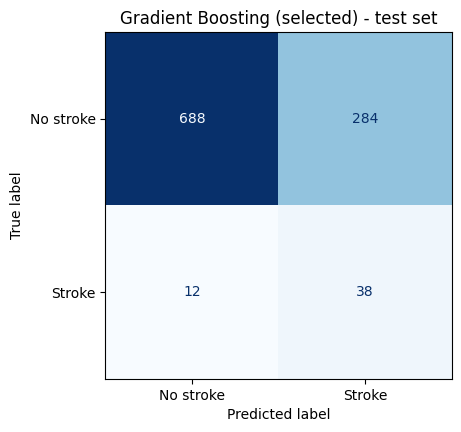

In [21]:
# The ONLY place the test set is used. Run this once.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

final_model = clone(pipe).set_params(**BEST_PARAMS)
t0 = time.perf_counter()
final_model.fit(X_train, y_train, model__sample_weight=compute_sample_weight("balanced", y_train))
final_fit_t = time.perf_counter() - t0

t0 = time.perf_counter()
test_proba = final_model.predict_proba(X_test)[:, 1]
final_pred_t = time.perf_counter() - t0
test_pred = (test_proba >= THRESHOLD).astype(int)

test_auc = roc_auc_score(y_test, test_proba)
test_prec = precision_score(y_test, test_pred, zero_division=0)
test_rec = recall_score(y_test, test_pred)
flagged = test_pred.mean()
tp = int(((test_pred == 1) & (y_test == 1)).sum())

print("Selected: balanced weights, n_estimators=50, learning_rate=0.1, max_depth=1, threshold={}".format(THRESHOLD))
print("Test ROC AUC : {:.3f}".format(test_auc))
print("Test recall  : {:.3f}  ({} of {} strokes caught)".format(test_rec, tp, int(y_test.sum())))
print("Test precision: {:.3f}".format(test_prec))
print("Share flagged: {:.1%}".format(flagged))
print("Constraint (recall >= {:.0%}): {}".format(RECALL_TARGET, "MET" if test_rec >= RECALL_TARGET else "NOT MET"))
print("Fit time {:.3f}s | predict time on {} rows {:.4f}s | {}".format(final_fit_t, len(X_test), final_pred_t, RUNTIME))
print()
print(classification_report(y_test, test_pred, zero_division=0))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, ax=ax, colorbar=False,
                                        display_labels=["No stroke", "Stroke"], cmap="Blues")
ax.set_title("Gradient Boosting (selected) - test set")
plt.show()

### CONCLUSION

### Decision log: Gradient Boosting

**Selected:** balanced sample weights, 50 trees, learning rate 0.1, depth 1, threshold 0.5.

**Why.** Without weights, validation recall was only 4%, because about 5% of rows are strokes and the model learned to predict "no stroke". Balanced weights raised it to 65.9% untuned and 86.0% tuned. Tuning added little to ROC AUC (0.8516 vs 0.8485 for the baseline, with a fold spread of about 0.03), so the recall gain comes mainly from the weights. The tuned unweighted model had a slightly higher AUC (0.8549) but only 1.5% recall at threshold 0.5, so it was not selected. Depth-1 trees also overfit least (train/validation AUC gap 0.013 vs 0.103 for the baseline) and fit fastest (0.17 s vs 1.14 s).

**Test result (scored once).** ROC AUC 0.816, recall 76% (38 of 50 strokes), precision 11.8%, and 31.5% of people flagged. The 80% recall constraint was NOT met. Validation recall was 86%, but with only 50 positive cases the test estimate is uncertain by roughly 12 percentage points either way, so the gap is within noise.

**Trade-off.** The model catches about three in four strokes but flags about 3 in 10 people, so most alerts are false positives. That is only acceptable if a follow-up check is cheap.

**What would change this.** A lower threshold would raise recall but flag more people. A larger dataset would give a more reliable recall estimate.